# Genome browser tracks

`epi.pl.plot_browser_track` ports ArchR's `plotBrowserTrack`: one normalised
pseudo-bulk ATAC track per cell group, plus peak, loop (co-accessibility /
peak-to-gene) and gene tracks, with the same layout and colours as ArchR.

Coverage is read directly from tabix-indexed fragment files, so you do not
need BigWigs. On the same cells and fragments, the numbers match ArchR 1.0.3 tile for tile
(see the parity summary at the end).

## How the coverage is computed

This is ArchR's `.groupRegionSumArrows`, reproduced exactly:

1. Groups with fewer than `min_cells` cells are dropped. Groups larger than
   `max_cells` are subsampled with R's `sample()`. Epione reimplements R's RNG,
   so `seed=1` picks the same cells as ArchR after `set.seed(1)`.
   ArchR switches R to `L'Ecuyer-CMRG` whenever `addArchRThreads(threads > 1)`;
   this is `rng="archr"`, the default.
2. The window is cut into `tile_size` bp tiles. For each cell and tile, the
   value is 1 if at least one fragment **starts** in that tile. ArchR 1.0.3
   computes both of its tile indices from the fragment start, so ends are not
   counted. Pass `count_ends=True` to also count the end tile.
3. Per group, the cell counts are summed. They are then scaled by
   `1e4 / sum(norm column)` over the group's cells (`norm_method`;
   ArchR's default is `ReadsInTSS`).
4. For plotting, the signal is clipped at its 0.999 quantile, and all groups
   share one y-axis.

In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import epione as epi

mpl.rcParams['figure.dpi'] = 90
DATA = Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))

## Data

We use the ArchR hematopoiesis data (BMMC, CD34+ BMMC and PBMC, hg19)
preprocessed entirely with Epione. The dataset tutorial
[`t_archr_heme_data`](t_archr_heme_data.ipynb) downloads the fragments with
`epi.datasets.archr_hematopoiesis` and builds every file used here. Set
`EPIONE_ARCHR_HEME` to the directory it wrote; the default is
`data_archr_heme/` next to this notebook.

* `heme_peaks.h5ad` — cells × peaks counts, Leiden `Clusters`, per-cell QC and
  the `X_iterative_lsi` embedding;
* `HemeFragments/<sample>.fragments.tsv.gz` — the three tabix-indexed fragment
  files as downloaded. Cell names follow ArchR's `Sample#barcode` convention,
  which is how cells are matched to the per-sample files.

ArchR normalises by `ReadsInTSS`. This dataset stores the number of unique
fragments per cell (`n_fragment`), so we normalise by `nFrags`.

In [2]:
%%time
adata = ad.read_h5ad(DATA / 'heme_peaks.h5ad')
adata.obs['nFrags'] = adata.obs['n_fragment']

fragments = {s: str(DATA / 'HemeFragments' / f'{s}.fragments.tsv.gz')
             for s in sorted(adata.obs['Sample'].astype(str).unique())}
peaks = adata.var[['chrom', 'start', 'end']]
print(adata)
adata.obs[['Sample', 'Clusters', 'nFrags', 'tsse']].head()

AnnData object with n_obs × n_vars = 10705 × 232272
    obs: 'Sample', 'n_fragment', 'tsse', 'frac_dup', 'frac_mito', 'Clusters', 'FRIP', 'nFrags'
    var: 'chrom', 'start', 'end', 'gc_bias'
    uns: 'bg_peaks_params', 'files', 'motif_deviations_names', 'motif_deviations_params', 'motif_names', 'motif_params', 'peak_seq', 'reference_sequences'
    obsm: 'X_iterative_lsi', 'X_umap', 'motif_deviations', 'motif_deviations_raw'
    varm: 'bg_peaks', 'motif'
CPU times: user 300 ms, sys: 247 ms, total: 547 ms
Wall time: 556 ms


,Sample,Clusters,nFrags,tsse
scATAC_BMMC_R1#AAACGAAAGCACGTAG-1,scATAC_BMMC_R1,C9,1555,27.227723
scATAC_BMMC_R1#AAACGAAAGGCCAGTA-1,scATAC_BMMC_R1,C1,1266,14.026403
scATAC_BMMC_R1#AAACGAAAGGTTGTTC-1,scATAC_BMMC_R1,C8,1662,11.661166
scATAC_BMMC_R1#AAACGAAGTCTGCGCA-1,scATAC_BMMC_R1,C5,3421,29.438944
scATAC_BMMC_R1#AAACGAAGTGATGCTT-1,scATAC_BMMC_R1,C8,2419,70.721358


In [3]:
adata.obs['Clusters'].value_counts().sort_index()

Clusters
C1     2474
C2     1566
C3     1324
C4     1282
C5      943
C6      907
C7      511
C8      476
C9      439
C10     410
C11     373
Name: count, dtype: int64

Gene and exon tracks come from the Gencode annotation of
`epi.utils.genome.hg19` (protein-coding genes; downloaded on first use).
`epi.utils.get_gene_annotation` returns one row per gene, so the exons, which
ArchR draws for every transcript, are read straight from the GFF3.

In [4]:
%%time
import gzip
genes = epi.utils.get_gene_annotation(epi.utils.genome.hg19).rename(columns={'gene_name': 'symbol'})

rows = []
with gzip.open(epi.utils.genome.hg19.annotation, 'rt') as fh:
    for line in fh:
        if line.startswith('#'):
            continue
        f = line.rstrip('\n').split('\t')
        if len(f) < 9 or f[2] != 'exon':
            continue
        attr = dict(kv.split('=', 1) for kv in f[8].split(';') if '=' in kv)
        if attr.get('gene_type') == 'protein_coding':
            rows.append((f[0], int(f[3]), int(f[4]), f[6], attr['gene_name']))
exons = pd.DataFrame(rows, columns=['chrom', 'start', 'end', 'strand', 'symbol']).drop_duplicates()
print(f'{len(genes):,} genes, {len(exons):,} exons')

20,109 genes, 294,551 exons
CPU times: user 12.7 s, sys: 687 ms, total: 13.4 s
Wall time: 15.1 s


### Co-accessibility loops

Loops can be any table with `chrom/start/end/value` columns. Here we compute
co-accessibility with `epi.tl.coaccessibility` (500 kNN metacells on the LSI,
peak pairs within 250 kb) and keep links with r ≥ 0.5 at 1 kb resolution,
like ArchR's `getCoAccessibility(corCutOff = 0.5, resolution = 1000)`.

Each pair's correlation only depends on the two peaks, so we restrict the
computation to peaks within 1 Mb of the genes plotted below.

In [5]:
%%time
GENES = ['CD34', 'GATA1', 'MS4A1', 'LYZ', 'CD3D']
near = np.zeros(adata.n_vars, bool)
for g in GENES:
    chrom, start, end = epi.pl._browser_track.gene_region(genes, g)
    near |= ((adata.var['chrom'] == chrom) & (adata.var['end'] > start - 1_000_000)
             & (adata.var['start'] < end + 1_000_000)).to_numpy()
co = epi.tl.coaccessibility(adata[:, near].copy(), use_rep='X_iterative_lsi', inplace=False, seed=1, verbose=False)
loops = epi.pl._browser_track.loops_from_coaccessibility(co, min_correlation=0.5, resolution=1000)
print(f'{near.sum():,} peaks, {len(co):,} pairs tested, {len(loops):,} loops with r >= 0.5')
loops.head()

1,536 peaks, 70,302 pairs tested, 1,689 loops with r >= 0.5
CPU times: user 997 ms, sys: 288 ms, total: 1.29 s
Wall time: 913 ms


,chrom,start,end,value
0,chr11,118209500,118213500,0.867139
1,chr11,117781500,117805500,0.859283
2,chr11,118691500,118754500,0.848527
3,chr11,60753500,60789500,0.831038
4,chr11,118209500,118230500,0.830579


## A full browser track

Pass `gene=` to centre the window on the TSS, with `upstream`/`downstream`
50 kb by default, as in ArchR. Passing loops as a dict sets the name of the
loop track.

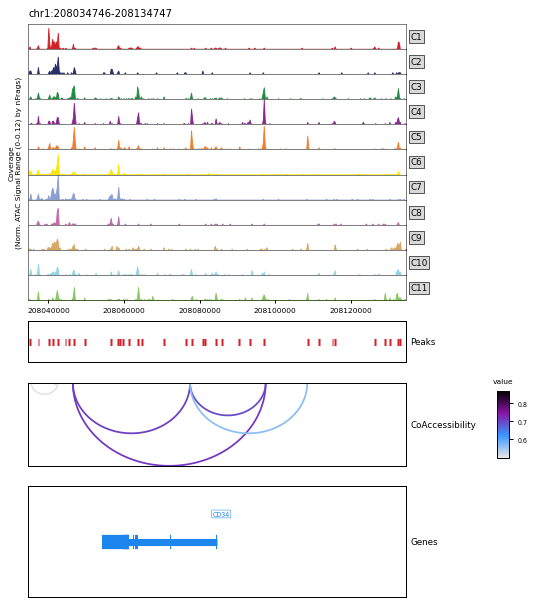

In [6]:
fig = epi.pl.plot_browser_track(
    adata, gene='CD34',
    fragments=fragments, group_by='Clusters', norm_method='nFrags',
    features=peaks, loops={'CoAccessibility': loops},
    gene_annotation=genes, exon_annotation=exons,
    show=False,
)
plt.show()

## Several marker genes

`plot_summary` selects which tracks to draw. Below we skip the loop track to
keep the figures compact.

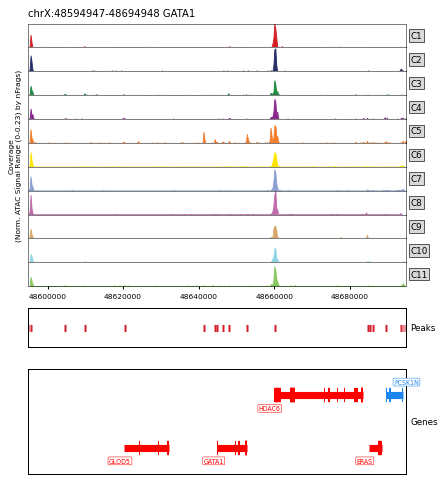

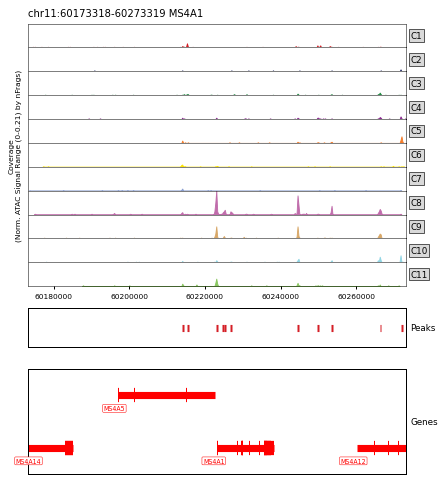

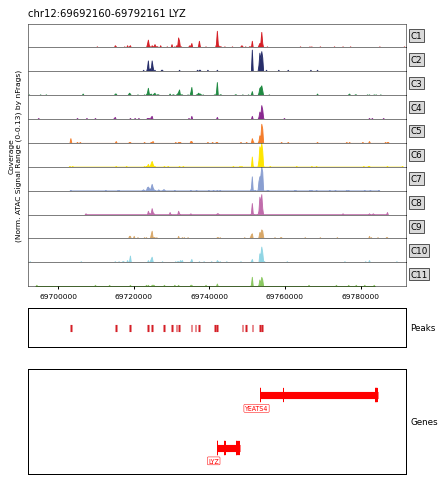

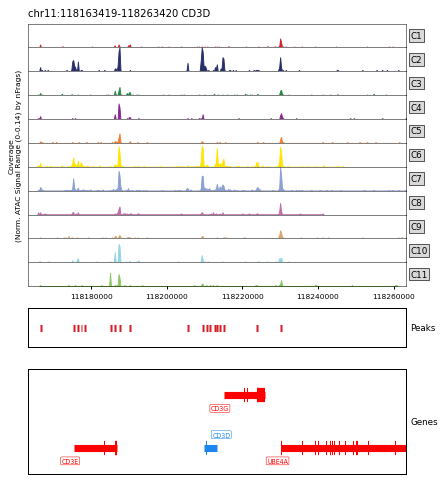

In [7]:
for g in GENES[1:]:
    fig = epi.pl.plot_browser_track(
        adata, gene=g, fragments=fragments, norm_method='nFrags',
        features=peaks, gene_annotation=genes, exon_annotation=exons,
        plot_summary=('bulkTrack', 'featureTrack', 'geneTrack'), sizes=(10, 1.5, 4),
        figsize=(6, 5.5), title=g, show=False,
    )
    plt.show()

## Subsets, explicit regions and highlights

* `use_groups` restricts the tracks to a subset of groups and sets their order.
* `region` takes `'chr:start-end'` or `(chrom, start, end)` in 1-based closed
  coordinates, the same as ArchR's GRanges.
* `highlight` shades intervals in every track.

The Leiden cluster IDs are not ArchR's, so we pick the groups from the data:
for each marker, the cluster with the highest mean gene score
(`heme_gene_scores.h5ad`).

In [8]:
gs = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
markers = ['CD34', 'GATA1', 'MS4A1', 'CD14', 'CD3D']
score = pd.DataFrame(np.log2(gs[:, markers].X.toarray() + 1), index=gs.obs_names, columns=markers)
mean = score.groupby(gs.obs['Clusters'].astype(str).to_numpy()).mean()
top = mean.idxmax()
display(top.rename('top cluster').to_frame().T)
use_groups = list(dict.fromkeys(top))   # one group per marker, in marker order
del gs

,CD34,GATA1,MS4A1,CD14,CD3D
top cluster,C3,C5,C8,C1,C6


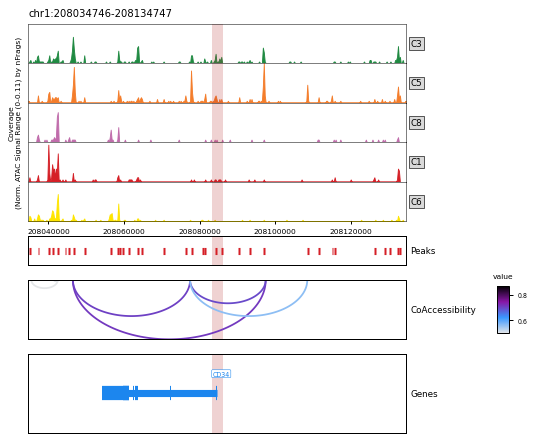

In [9]:
chrom, start, end = epi.pl._browser_track.gene_region(genes, 'CD34')
tss = (start + end) // 2
highlight = pd.DataFrame({'chrom': [chrom], 'start': [tss - 1_500], 'end': [tss + 1_500]})
fig = epi.pl.plot_browser_track(
    adata, region=f'{chrom}:{start}-{end}',
    fragments=fragments, use_groups=use_groups, norm_method='nFrags',
    features=peaks, loops={'CoAccessibility': loops},
    gene_annotation=genes, exon_annotation=exons, highlight=highlight,
    figsize=(6, 5), show=False,
)
plt.show()

## Interactive browser (igv.js)

`epi.pl.igv_browser` takes the same arguments as `plot_browser_track` and
returns an interactive [igv.js](https://github.com/igvteam/igv.js) browser:
drag to pan, scroll or use the toolbar to zoom, click a feature or arc for its
details, and use the camera button to save the current view as SVG or PNG.
To switch between the static and the interactive view, change the function
name. A few arguments differ: `genome` names the igv.js reference
(here `hg19`, which also adds igv's RefSeq gene track), and `ylim` is an
absolute range, not a quantile. Without `ylim` all coverage tracks share one
autoscaled y-axis, as in ArchR.

The coverage is computed by the same code as the static track
(`browser_track_coverage`, so it is the same numbers). All data for the window
plus `flank` bp on each side (by default half the window) is written into the
page as gzipped `data:` URIs, so the browser below works in the rendered docs
with no server and no local file paths. If you pan past the embedded window,
the tracks are empty; call it again with a new region.


In [10]:
igv = epi.pl.igv_browser(
    adata, gene='CD34',
    fragments=fragments, group_by='Clusters', norm_method='nFrags',
    features=peaks, loops={'CoAccessibility': loops},
    gene_annotation=genes, exon_annotation=exons, highlight=highlight,
    genome='hg19', title='CD34',
)
igv

IGVBrowser(locus='chr1:208034747-208134747', tracks=['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'Peaks', 'CoAccessibility', 'Genes'])

The returned `IGVBrowser` is a plain igv.js configuration. `.tracks` lists
the track dicts (you can edit them before displaying), and `.save()` writes a
standalone HTML page that you can open in any browser or attach to a report.

Other inputs work the same way:

* `bigwig_files={group: path}`: BigWigs from `epi.single.pseudobulk_with_fragments`.
  Local files are read over the window and embedded. Remote URLs are streamed by igv.js.
* `links=`: the `epi.tl.peak_to_gene` table, filtered by `fdr_thresh` /
  `min_abs_r` as in `plot_peak2gene`.
* `motifs=` / `footprints=`: motif sites, `epi.tl.hint_footprints` calls or
  BINDetect `*_bound.bed` files.
* `hic=`: a `.hic` URL (drawn natively by igv.js), a `.cool`/`.mcool` file (the
  strongest contacts in the window are drawn as arcs) or a BEDPE loop table.
* `tracks=`: any extra igv.js track configs.


In [11]:
print(igv)
pd.DataFrame([{k: v for k, v in t.items() if k != 'url'} for t in igv.tracks]).fillna('')

IGVBrowser(locus='chr1:208034747-208134747', tracks=['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'Peaks', 'CoAccessibility', 'Genes'])


,name,type,format,color,height,autoscale,autoscaleGroup,displayMode,arcType,valueColumn,showBlocks,searchable
0,C1,wig,bedgraph,#D51F26,40,True,coverage,,,,,
1,C2,wig,bedgraph,#272E6A,40,True,coverage,,,,,
2,C3,wig,bedgraph,#208A42,40,True,coverage,,,,,
3,C4,wig,bedgraph,#89288F,40,True,coverage,,,,,
4,C5,wig,bedgraph,#F47D2B,40,True,coverage,,,,,
5,C6,wig,bedgraph,#FEE500,40,True,coverage,,,,,
6,C7,wig,bedgraph,#8A9FD1,40,True,coverage,,,,,
7,C8,wig,bedgraph,#C06CAB,40,True,coverage,,,,,
8,C9,wig,bedgraph,#D8A767,40,True,coverage,,,,,
9,C10,wig,bedgraph,#90D5E4,40,True,coverage,,,,,


In [12]:
out = igv.save(DATA / 'igv_CD34.html')
print(Path(out).name, f'{Path(out).stat().st_size / 1e3:.0f} kB')

igv_CD34.html 18 kB


## The underlying numbers

`epi.pl.browser_track_coverage` returns the long-format table that the
coverage track is drawn from. It mirrors ArchR's data frame row for row:
non-zero tiles, the zero-valued flanking tiles used by `geom_area`, and
ArchR's padding row past the last tile (`x = NaN`). The cells actually used
are in `.attrs['cells']`.

In [13]:
region = epi.pl._browser_track.gene_region(genes, 'MS4A1')
cov = epi.pl.browser_track_coverage(adata, region, fragments=fragments, group_by='Clusters',
                                    norm_method='nFrags')
print(region, len(cov), 'rows,', len(cov.attrs['cells']), 'cells')
cov.groupby('group')['y'].agg(['max', 'sum']).round(3)

('chr11', 60173319, 60273319) 689 rows, 5198 cells


,max,sum
group,,
C1,0.036,0.298
C10,0.060,0.349
C11,0.065,0.316
C2,0.017,0.083
C3,0.022,0.220
C4,0.023,0.213
C5,0.057,0.195
C6,0.020,0.122
C7,0.018,0.081


## Parity vs ArchR

The port was checked against ArchR 1.0.3 `plotBrowserTrack` on ArchR's own
hematopoiesis project (10,660 cells, ArchR's `Clusters` C1–C11, the same three
fragment files) for CD34, GATA1, MS4A1, LYZ and CD3D, with `tileSize = 250`,
`normMethod = "ReadsInTSS"`, `minCells = 25`, `maxCells = 500`,
`addArchRThreads(8)` and `set.seed(1)`. The gates were registered before the
first comparison (`tests/parity/browser_track/MANIFEST.md`). The ArchR
reference outputs are generated outside this repository;
`tests/test_browser_track.py` re-runs the comparison when
`EPIONE_ARCHR_PARITY_DIR` points at them.

| # | Output | Gate | Result (worst of 5 genes) |
|---|---|---|---|
| 1 | Region from gene symbol | exact | identical ✅ |
| 2 | Group coverage, ArchR's sampled cells injected | max \|Δ\| ≤ 1e-8 | 4.9e-15 ✅ |
| 3 | Clipped plot data (0.999 quantile) | max \|Δ\| ≤ 1e-8 | 4.9e-15 ✅ |
| 4 | Group coverage, free-running numpy RNG | Pearson r ≥ 0.95 | 0.937 ❌ |
| 5 | Peaks overlapping the region | exact | identical ✅ |
| 6 | Group coverage, free-running `seed=1, rng="archr"` | same cells, max \|Δ\| ≤ 1e-8 | same cells, 4.9e-15 ✅ |
| 7 | Gene rows (packing) and clipped coordinates | exact | identical ✅ |
| 8 | Loop arc geometry | max \|Δ\| ≤ 1e-6 | 5.4e-7 ✅ |
| 9 | Group palette | exact | identical ✅ |

The largest coverage difference is double-precision rounding, and loop
coordinates agree to the precision of R's text export.

The `maxCells` subsampling is the only random step, and row 4 shows how much
the track depends on *which* cells are drawn. ArchR is not reproducible to
that level either: its own `set.seed(1)` and `set.seed(2)` draws correlate at
r = 0.925–0.980 across the five genes, and five numpy seeds give 0.916–0.982
against ArchR. The gate stays failed as registered. This is why Epione ports
R's RNG (`rng="archr"`, row 6) instead of only matching distributions.

## Notes

* The fragment files must be tabix-indexed (`epi.pp.ensure_tabix_index`).
  Fragment-file starts are 0-based; Epione adds 1, exactly as ArchR does when
  it builds Arrow files.
* `norm_method` accepts `ReadsInTSS` (default), `ReadsInPromoter`, `nFrags`
  (any of these needs the column in `adata.obs`), `nCells` and `None`.
* `ylim` uses ArchR's semantics: it gives *quantiles* of the signal, not
  absolute values.
* Set `rng="R"` to reproduce an ArchR session run with `threads = 1`, which
  keeps R's default Mersenne-Twister. Set `rng="numpy"` for a plain numpy
  draw.